# Proches en métro, proches en revenus ?

## *La géographie du réseau de transports en communs en Île-de-France reflète-t-elle la géographie des inégalités de revenus dans la région ?*

## Introduction

*De la Plaine Monceau au quartier des Épinettes on parcourt tout l'espace social, la transition entre les extrêmes étant assurée par un glacis de classes moyennes. Ces contrastes sociaux importants voisinent pourtant à quelques rues près, même si la mixité sociale est menacée par un processus d'embourgeoisement qui fait tache d'huile et ne laisse guère de quartiers à l'écart.*

*Du sud-ouest au nord-est du 17e arrondissement, le parcours est à la fois historique et sociologique, des abords fortunés du parc Monceau aux confins bordés par les boulevards des Maréchaux et leurs HBM (Habitations à bon marché, ancêtres des HLM).*

Pinçon, M. et Pinçon-Charlot, M. (2014). I. Lire Paris. Sociologie de Paris (3e éd., p. 9-26). La Découverte. https://shs.cairn.info/sociologie-de-paris--9782707182623-page-9?lang=fr.

Parce qu'elles sont conçues pour relier des territoires différents, les lignes de transports en commun traversent logiquement des espaces socialement et économiquement hétérogènes. Ainsi, par exemple, l'usager quotidien de la ligne 4 ou du RER A n'occupe pas la même position dans l'échelle sociale selon qu'il se trouve au milieu ou à l'une des extrémités de ces lignes.

Si des territoires économiquement et socialement proches peuvent aussi l'être géographiquement, les transports en commun rapprochent des espaces parfois très différentes, et constituent ainsi des axes le long desquels peuvent s'observer les contrastes.

Nous développons ici deux axes de réponse à cette question. Nous verrons dans un premier temps que les revenus tendent à décroître à mesure que l'excentricité par rapport au réseau augmente, y compris à distance géographique équivalente. Dans un second temps, nous verrons que le long de certaines lignes, des stations très proches affichent des revenus moyens très différents.

## Données

Les deux principales sources de données utilisées pour ce projet sont les données IDFM et les données Filosofi.

In [58]:
from pretraitement_donnees import telecharger_zip, URL_ZIP_FILOSOFI, URL_ZIP_IDFM
import numpy as np
import os
import pandas as pd

### Données FiLoSoFi

Les données FiLoSoFi sont les données carroyées de niveau de vie calculées par l'Insee. 

In [59]:
from pretraitement_donnees import charger_filosofi, indicateurs_filosofi, definir_quantiles, construire_centres_carreaux

telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")


### Données IDFM

In [ ]:
from pretraitement_donnees import charger_arrets, charger_routes, charger_horaires, charger_parcours, charger_stations, charger_trips, construire_lignes_idfm, construire_stations, construire_positions_stations, construire_aretes, construire_graphe_reseau

# telecharger_zip(URL_ZIP_IDFM, "idfm")
print(os.listdir("data/idfm"))

['transfers.txt', 'agency.txt', 'calendar_dates.txt', 'stop_times.txt', 'shapes.txt', 'object_codes_extension.txt', 'trips.txt', 'ticketing_deep_links.txt', 'attributions.txt', 'pathways.txt', 'stops.txt', 'booking_rules.txt', 'calendar.txt', 'routes.txt']


Les données IDFM ne contiennent pas moins de 14 fichiers .txt différents, au format CSV. Nous ne chargeons que ceux dont nous avons besoin pour construire les lignes et calculer les temps de trajet entre deux stations. 

In [ ]:
print(len(pd.read_csv("data/idfm/routes.txt"))) 

2027


Il y a 2027 lignes différentes. Pour faciliter la visualisation et les traitements, nous décidons de ne garder que les lignes de métro et de RER.

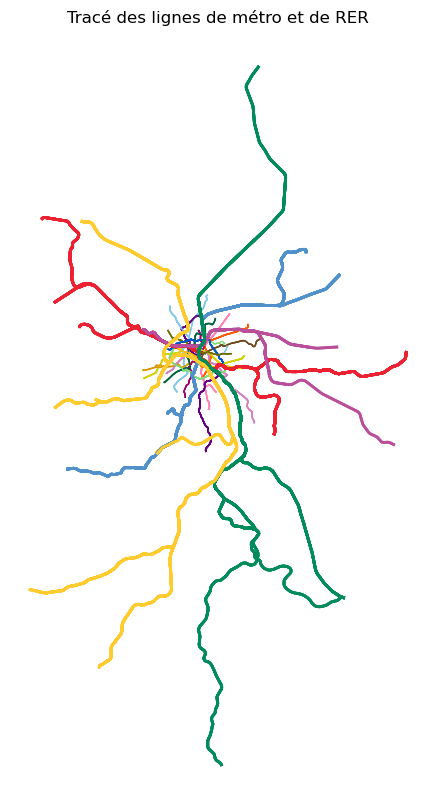

In [ ]:
df_routes = charger_routes("data/idfm") # Lignes selon leur type, nous ne gardons que métro et RER
df_trips = charger_trips("data/idfm", df_routes) # Trains qui traversent chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips) # Géométrie du parcours suivi par les trains de notre sélection

gpd_idfm = construire_lignes_idfm(df_parcours) # Passage en GeoPandas, avec changement de projection

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"], # Couleurs officielles des lignes
    linewidth=np.where(gpd_idfm["mode"] == "metro", 1, 2), # RER plus épais
    figsize=(10, 10),
)
ax.set_title("Tracé des lignes de métro et de RER")
ax.set_axis_off()

Nous obtenons un DataFrame qui indique le tracé géographique de chaque ligne de métro / RER. De la même manière, nous construisons le graphe du réseau à partir des temsp de transport d'une station à une autre. Les sommets sont donc les stations, et les sommets les arêtes.

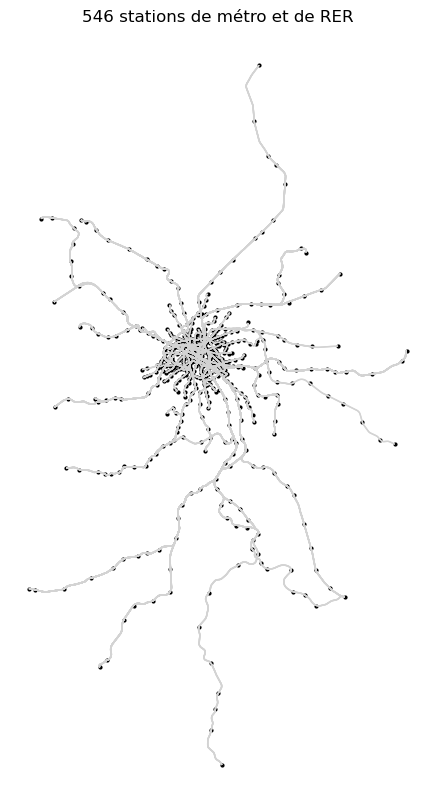

In [55]:
df_arrets = charger_arrets("data/idfm", df_trips) # Arrêts desservis par les trains
df_stations = charger_stations("data/idfm", df_arrets) # Stations desservies par les trains (plusieurs arrêts pour une même station)
gpd_stations = construire_stations(df_stations) # Construction de la position des stations

ax = gpd_idfm.plot(color="lightgrey", linewidth=1, figsize=(10, 10)) # Lignes en fond
gpd_stations.plot(ax=ax, color="black", markersize=4)
ax.set_title(f"{len(gpd_stations)} stations de métro et de RER")
ax.set_axis_off()

In [54]:
df_horaires = charger_horaires("data/idfm", df_trips) # Horaires des trains à chaque arrêt
df_aretes = construire_aretes(df_horaires) # Calcul du temps minimal entre deux stations consécutives
graphe_reseau = construire_graphe_reseau(df_aretes) # Graphe orienté pondéré par le temps de transport entre les stations

print(graphe_reseau)

DiGraph with 546 nodes and 1313 edges


Nous retrouvons bien 546 stations avec 1313 trajets entre deux stations, ce qui indique que nous comptons les trajets dans les deux sens et les correspondances.

## Méthodologie

## I. Temps en transports, distance géographique, proximité économique

Dans cette partie, nous calculons pour chaque station le temps de transport par rapport à plusieurs pôles, et définissons comme temps de transport de référence le temps le moins élevé.

## II. Écarts entre des stations consécutives, hétérogénéité des lignes